# 자원최적화 데이터 진단 노트북 (01)

- 데이터: `data/okm_augumented_2021.csv` (KAMP 자원 최적화 AI 데이터셋)
- 출처 표기: 중소벤처기업부, KAMP, 자원 최적화 AI 데이터셋, KAIST(울산과학기술원, ㈜유피시앤에스), 2021.12.27., www.kamp-ai.kr
- 목적: 모델링 전에 **행 단위, 시간 순서, 결측, 복제(augmented) 구조**를 확인하고, 누수 없이 쓸 수 있는 구간을 정의한다.
- 원칙: 이 노트북은 어떤 값도 학습(fit)하지 않는다. 진단과 플래그 부여만 한다.
- 각 셀 끝의 **굵은 결론**은 코드가 계산한 값으로 출력된다 (재실행 시 값이 바뀌면 결론도 바뀜).

In [15]:
# 0. 환경
import platform, json, sys
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = f; break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

def conclude(s):
    display(Markdown(f'**결론: {s}**'))

env = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
       'matplotlib': matplotlib.__version__, 'os': platform.system(), 'font': plt.rcParams['font.family']}
print(json.dumps(env, ensure_ascii=False))

{"python": "3.12.10", "numpy": "1.26.4", "pandas": "2.2.2", "matplotlib": "3.9.2", "os": "Windows", "font": ["Malgun Gothic"]}


## 1. 불러오기와 변수 정의

,컬럼,가이드북 정의(요지)
0,날짜/시간,공장운영 날짜/시간
1,15분·30분·45분·60분,각 15분 구간의 피크전기 사용량
2,평균,4구간 평균
3,생산량,해당 시점에 생산해야 할 생산량(ERP)
4,기온·풍속·습도·강수량,기상청 데이터
5,전기요금(계절),해당 시점 전기요금(한전 자료)
6,day/d/m,요일/일/월
7,공장인원,해당 시점 공장 보유 생산력
8,인건비,주·야간 인건비 비율


(6168, 20)


,날짜,시간,15분,30분,45분,60분,평균,생산량,기온,풍속,습도,강수량,전기요금(계절),day,d,m,공장인원,인건비,date,row_h
0,20210101,0,62,61,61,61,61,0,-3.2,2.4,71,0.0,109.8,5,1,1,0.0,1.5,2021-01-01,0
1,20210101,1,96,93,116,113,105,0,-4.5,1.5,77,0.0,109.8,5,1,1,0.0,1.5,2021-01-01,1
2,20210101,2,106,96,106,107,104,0,-3.9,2.6,58,0.0,109.8,5,1,1,0.0,1.5,2021-01-01,2


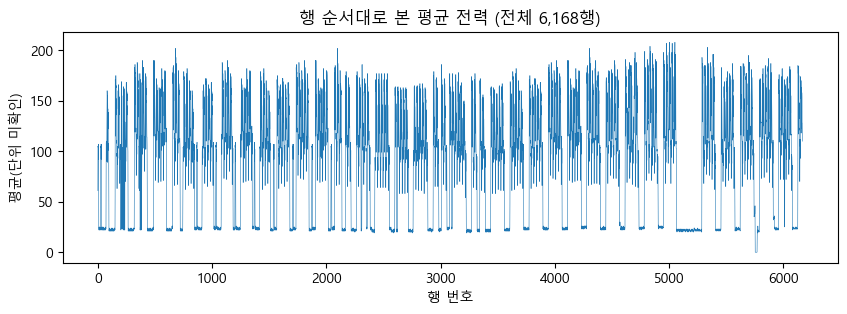

**결론: 6,168행 × 18열, 257일. 전력 단위는 가이드북에 명시가 없어 "단위 미확인"으로 표기한다**

In [16]:
raw = pd.read_csv('data/okm_augumented_2021.csv', encoding='utf-8-sig')
df = raw.copy()
df['date'] = pd.to_datetime(df['날짜'].astype(str), format='%Y%m%d')
df['row_h'] = df.groupby('날짜').cumcount()          # 날짜 안에서의 행 순번 (0~23)
P = ['15분', '30분', '45분', '60분']                    # 한 시간 안의 15분 구간별 최대수요전력

defs = pd.DataFrame({
 '컬럼': ['날짜/시간', '15분·30분·45분·60분', '평균', '생산량', '기온·풍속·습도·강수량', '전기요금(계절)', 'day/d/m', '공장인원', '인건비'],
 '가이드북 정의(요지)': ['공장운영 날짜/시간', '각 15분 구간의 피크전기 사용량', '4구간 평균', '해당 시점에 생산해야 할 생산량(ERP)',
                  '기상청 데이터', '해당 시점 전기요금(한전 자료)', '요일/일/월', '해당 시점 공장 보유 생산력', '주·야간 인건비 비율']})
display(defs)
print(df.shape)
display(df.head(3))

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(df.index, df['평균'], lw=0.4)
ax.set_title('행 순서대로 본 평균 전력 (전체 6,168행)'); ax.set_xlabel('행 번호'); ax.set_ylabel('평균(단위 미확인)')
plt.show()
conclude(f'{df.shape[0]:,}행 × {raw.shape[1]}열, {df["날짜"].nunique()}일. 전력 단위는 가이드북에 명시가 없어 "단위 미확인"으로 표기한다')

## 2. 달력 검증: day·d·m이 날짜와 맞는가, 빠진 날이 있는가

,day == 요일(월=1),d == 일,m == 월
0,1.0,1.0,1.0


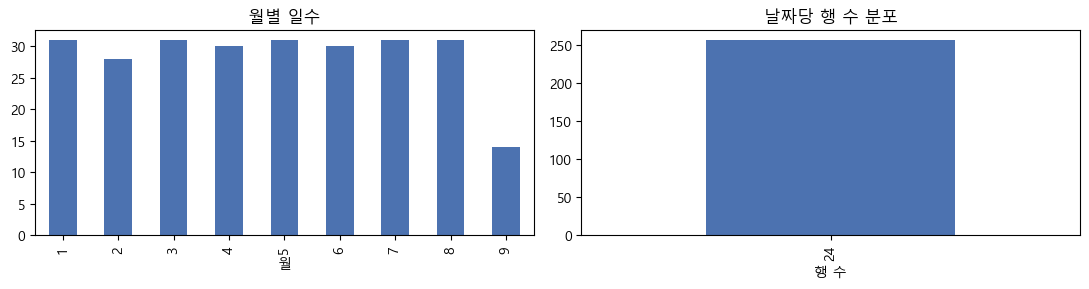

**결론: day·d·m 일치율 100%, 빠진 날 0일, 모든 날짜가 [24]행 → 1행 = 1시간, 한 행 안에 15분 구간 4개**

In [17]:
cal = pd.DataFrame({
  'day == 요일(월=1)': [(df['day'] == df['date'].dt.weekday + 1).mean()],
  'd == 일': [(df['d'] == df['date'].dt.day).mean()],
  'm == 월': [(df['m'] == df['date'].dt.month).mean()]})
display(cal)
full = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
missing_days = full.difference(df['date'].unique())
rows_per_day = df.groupby('날짜').size()

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
df.groupby(df['date'].dt.month)['날짜'].nunique().plot.bar(ax=ax[0], color='#4c72b0')
ax[0].set_title('월별 일수'); ax[0].set_xlabel('월')
rows_per_day.value_counts().plot.bar(ax=ax[1], color='#4c72b0')
ax[1].set_title('날짜당 행 수 분포'); ax[1].set_xlabel('행 수')
plt.tight_layout(); plt.show()
conclude(f'day·d·m 일치율 {cal.values.min():.0%}, 빠진 날 {len(missing_days)}일, 모든 날짜가 {rows_per_day.unique().tolist()}행 → 1행 = 1시간, 한 행 안에 15분 구간 4개')

## 3. `평균` 컬럼 검증

c:\Users\wm032\Documents\KAMP\plastic\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


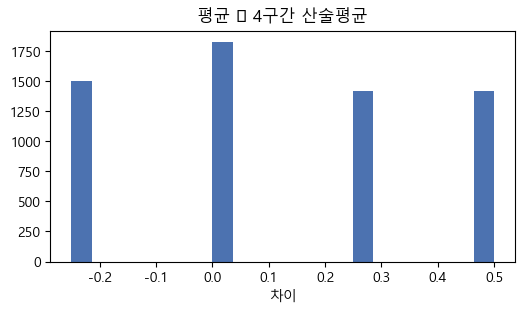

**결론: |차이| ≤ 0.5 비율 100.0% → `평균`은 4구간 평균의 정수 반올림(파생값). 입력·타깃에 15분 컬럼과 함께 쓰면 중복 정보**

In [18]:
m4 = df[P].mean(axis=1)
diff = (df['평균'] - m4)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(diff, bins=21, color='#4c72b0'); ax.set_title('평균 − 4구간 산술평균'); ax.set_xlabel('차이')
plt.show()
conclude(f'|차이| ≤ 0.5 비율 {(diff.abs() <= 0.5).mean():.1%} → `평균`은 4구간 평균의 정수 반올림(파생값). 입력·타깃에 15분 컬럼과 함께 쓰면 중복 정보')

## 4. `시간` 컬럼 오류 (0~23 범위 밖)
가이드북은 `pd.date_range(freq='H')`로 인덱스를 새로 만들어 행 순서를 시간으로 간주했다. 그 가정이 오류 날짜에서도 성립하는지 확인한다.

시간 ≠ 행순번 행 수: 48 날짜: [20210713, 20210715]
인건비 규칙(09~17시 1.0, 그 외 1.5) 위반 날짜: [20210713, 20210715]
날짜별 시간 vs 60분 순위상관: {20210713: 0.907, 20210715: 0.952}


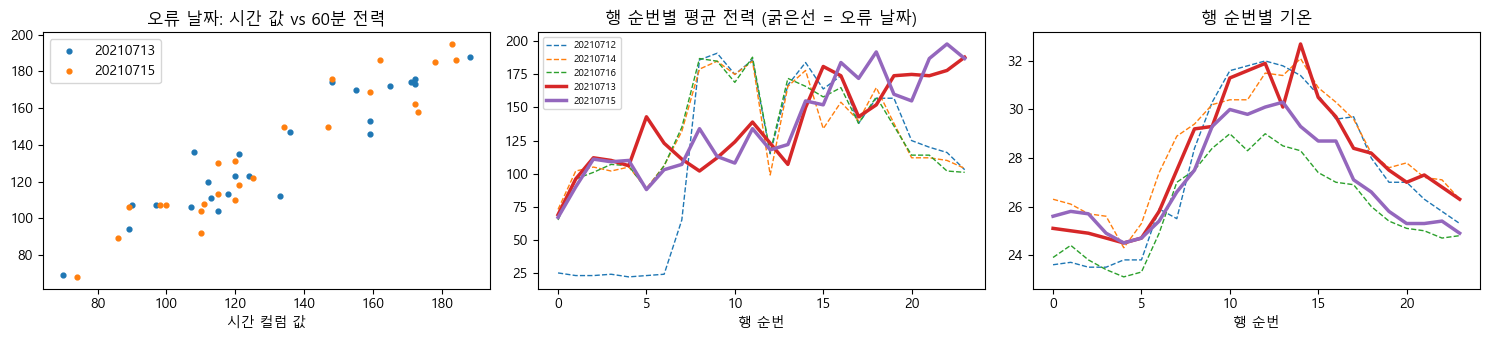

,요일,생산량합,인건비
날짜,,,
20210713,2,0,[1.5]
20210715,4,0,[1.5]


**결론: 오류 48행은 [20210713, 20210715] 이틀. 시간 값이 0~23이 아니라 전력과 순위상관 0.91~0.95인 증가 수열이고, 전력은 행 순번을 따라 밤까지 상승(다른 평일의 08시 피크 모양과 다름), 인건비는 종일 1.5, 평일인데 생산량 0. 기온은 정상 일주기 → 기상 열은 시간순, 전력 열의 시간 정렬은 확인 불가. 이 이틀의 전력은 시간 기반 분석에서 제외(플래그)한다**

In [19]:
bad_mask = (df['시간'] != df['row_h'])
bad_days = sorted(int(v) for v in df.loc[bad_mask, '날짜'].unique())
print('시간 ≠ 행순번 행 수:', bad_mask.sum(), '날짜:', bad_days)
exp_labor = np.where(df['row_h'].between(9, 17), 1.0, 1.5)
labor_bad_days = sorted(int(v) for v in df.loc[df['인건비'] != exp_labor, '날짜'].unique())
print('인건비 규칙(09~17시 1.0, 그 외 1.5) 위반 날짜:', labor_bad_days)

x = df[df['날짜'].isin(bad_days)]
sp = x.groupby('날짜')[['시간'] + P + ['평균']].corr(method='spearman').xs('시간', level=1)['60분']
print('날짜별 시간 vs 60분 순위상관:', sp.round(3).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for d in bad_days:
    xx = df[df['날짜'] == d]; ax[0].scatter(xx['시간'], xx['60분'], s=12, label=str(d))
ax[0].set_title('오류 날짜: 시간 값 vs 60분 전력'); ax[0].set_xlabel('시간 컬럼 값'); ax[0].legend()
for d in [20210712, 20210714, 20210716] + bad_days:
    xx = df[df['날짜'] == d]
    ax[1].plot(xx['row_h'], xx['평균'], lw=2.5 if d in bad_days else 1, ls='-' if d in bad_days else '--', label=str(d))
ax[1].set_title('행 순번별 평균 전력 (굵은선 = 오류 날짜)'); ax[1].set_xlabel('행 순번'); ax[1].legend(fontsize=7)
for d in [20210712, 20210714, 20210716] + bad_days:
    xx = df[df['날짜'] == d]
    ax[2].plot(xx['row_h'], xx['기온'], lw=2.5 if d in bad_days else 1, ls='-' if d in bad_days else '--', label=str(d))
ax[2].set_title('행 순번별 기온'); ax[2].set_xlabel('행 순번')
plt.tight_layout(); plt.show()

prod = df[df['날짜'].isin(bad_days)].groupby('날짜').agg(요일=('day', 'first'), 생산량합=('생산량', 'sum'), 인건비=('인건비', 'unique'))
display(prod)
conclude(f'오류 {bad_mask.sum()}행은 {bad_days} 이틀. 시간 값이 0~23이 아니라 전력과 순위상관 {sp.min():.2f}~{sp.max():.2f}인 증가 수열이고, '
         f'전력은 행 순번을 따라 밤까지 상승(다른 평일의 08시 피크 모양과 다름), 인건비는 종일 1.5, 평일인데 생산량 0. '
         f'기온은 정상 일주기 → 기상 열은 시간순, 전력 열의 시간 정렬은 확인 불가. 이 이틀의 전력은 시간 기반 분석에서 제외(플래그)한다')

## 5. 행 순서 = 시간 순서인가 (연속성 검증)

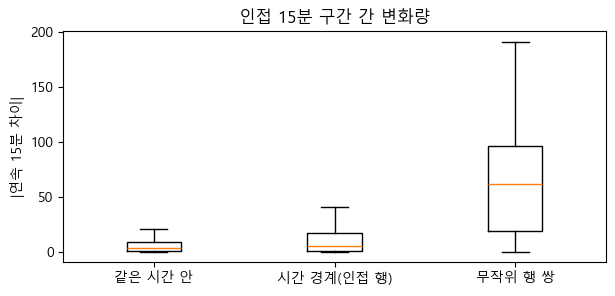

**결론: 평균 변화량: 같은 시간 안 6.7, 인접 행 경계 12.4, 무작위 64.4 → 인접 행은 무작위보다 훨씬 가까워 행 순서가 시간 흐름을 대체로 따름. 다만 경계 변화가 시간 안 변화의 1.8배 → 15분 4개가 완전히 연속된 계열인지는 단정 불가**

In [20]:
within = np.abs(np.diff(df[P].values, axis=1)).ravel()                 # 같은 시간 안 15분 → 15분
bnd = np.abs(df['15분'].values[1:] - df['60분'].values[:-1])            # 시간 경계 60분 → 다음 행 15분
rng = np.random.default_rng(SEED)
shuf = np.abs(df['15분'].values[1:] - rng.permutation(df['60분'].values[:-1]))
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([within, bnd, shuf], showfliers=False)
ax.set_xticks([1, 2, 3], ['같은 시간 안', '시간 경계(인접 행)', '무작위 행 쌍'])
ax.set_ylabel('|연속 15분 차이|'); ax.set_title('인접 15분 구간 간 변화량')
plt.show()
conclude(f'평균 변화량: 같은 시간 안 {within.mean():.1f}, 인접 행 경계 {bnd.mean():.1f}, 무작위 {shuf.mean():.1f} → 인접 행은 무작위보다 훨씬 가까워 행 순서가 시간 흐름을 대체로 따름. '
         f'다만 경계 변화가 시간 안 변화의 {bnd.mean()/within.mean():.1f}배 → 15분 4개가 완전히 연속된 계열인지는 단정 불가')

## 6. 결측

,결측 수,날짜(시각)
풍속,3,"20210601(1시), 20210601(2시), 20210704(20시)"
강수량,1,20210124(0시)
공장인원,17,"20210828(18시), 20210828(19시), 20210828(20시) ..."


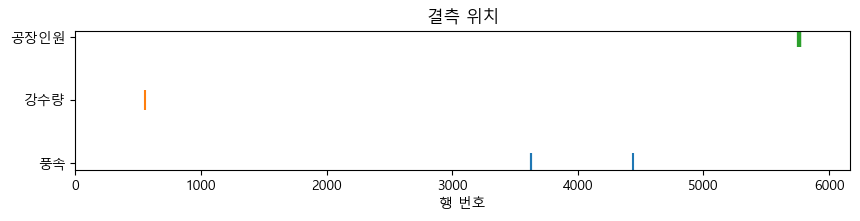

**결론: 결측 총 21칸. 공장인원 17칸은 20210828 18시 ~ 20210829 10시 연속 구간 → 무작위 결측이 아님. 보간은 모델링 단계에서 학습 구간 정보만으로 수행(여기서는 채우지 않음)**

In [21]:
na = df[['풍속', '강수량', '공장인원']].isna()
na_tbl = pd.DataFrame({'결측 수': na.sum(), '날짜(시각)': [
    ', '.join(f"{a}({b}시)" for a, b in df.loc[na[c], ['날짜', 'row_h']].values[:3]) + (' ...' if na[c].sum() > 3 else '') for c in na.columns]})
display(na_tbl)
fig, ax = plt.subplots(figsize=(10, 1.8))
for i, c in enumerate(na.columns):
    ax.scatter(df.index[na[c]], [i] * na[c].sum(), marker='|', s=200)
ax.set_yticks(range(3), na.columns); ax.set_xlim(0, len(df)); ax.set_xlabel('행 번호'); ax.set_title('결측 위치')
plt.show()
run = df.loc[na['공장인원'], ['날짜', 'row_h']]
conclude(f'결측 총 {int(na.values.sum())}칸. 공장인원 {na["공장인원"].sum()}칸은 {run.iloc[0,0]} {run.iloc[0,1]}시 ~ {run.iloc[-1,0]} {run.iloc[-1,1]}시 연속 구간 → 무작위 결측이 아님. '
         f'보간은 모델링 단계에서 학습 구간 정보만으로 수행(여기서는 채우지 않음)')

## 7. 복제(augmented) 구조: 하루 96개 전력값이 완전히 같은 날
파일명이 `augumented`다. 하루 프로파일(24시간 × 15분 4구간 = 96값)이 다른 날과 완전히 같은지 확인한다.

m,1,2,3,4,5,6,7,8,9
일수,31,28,31,30,31,30,31,31,14
고유일,4,0,3,0,14,2,29,31,14
복제묶음소속,27,28,28,30,17,28,2,0,0


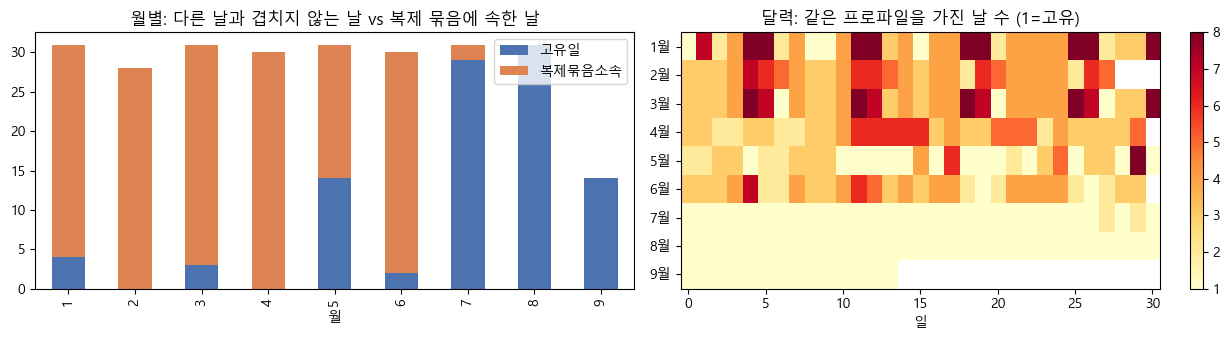

**결론: 257일 중 고유 프로파일 142개, 복제 묶음에 속한 날 160일. 1~6월은 대부분 서로 복제(고유일 1월 4, 2월 0, 3월 3, 4월 0, 5월 14, 6월 2), 7~9월은 거의 고유**

In [22]:
prof = df.pivot(index='날짜', columns='row_h', values=P)
key = prof.apply(lambda r: tuple(r.values), axis=1)
gid = key.map({k: i for i, k in enumerate(pd.unique(key))})
gsz = gid.map(gid.value_counts())
days = pd.DataFrame({'날짜': prof.index, 'date': pd.to_datetime(prof.index.astype(str)), 'grp': gid.values, 'grp_size': gsz.values})
days['m'] = days['date'].dt.month
days['dup'] = days['grp_size'] > 1

mon = days.groupby('m').agg(일수=('dup', 'size'), 고유일=('dup', lambda s: (~s).sum()), 복제묶음소속=('dup', 'sum'))
display(mon.T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
mon[['고유일', '복제묶음소속']].plot.bar(stacked=True, ax=ax[0], color=['#4c72b0', '#dd8452'])
ax[0].set_title('월별: 다른 날과 겹치지 않는 날 vs 복제 묶음에 속한 날'); ax[0].set_xlabel('월')
cal = np.full((9, 31), np.nan)
for _, r in days.iterrows():
    cal[r['m'] - 1, r['date'].day - 1] = min(r['grp_size'], 8)
im = ax[1].imshow(cal, aspect='auto', cmap='YlOrRd', vmin=1, vmax=8)
ax[1].set_yticks(range(9), [f'{i}월' for i in range(1, 10)]); ax[1].set_xlabel('일'); ax[1].set_title('달력: 같은 프로파일을 가진 날 수 (1=고유)')
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()
conclude(f'{len(days)}일 중 고유 프로파일 {gid.nunique()}개, 복제 묶음에 속한 날 {days["dup"].sum()}일. '
         f'1~6월은 대부분 서로 복제(고유일 1월 {mon.loc[1,"고유일"]}, 2월 {mon.loc[2,"고유일"]}, 3월 {mon.loc[3,"고유일"]}, 4월 {mon.loc[4,"고유일"]}, 5월 {mon.loc[5,"고유일"]}, 6월 {mon.loc[6,"고유일"]}), 7~9월은 거의 고유')

## 8. 복제 묶음의 성격: 가장 큰 묶음과 다른 컬럼의 일치 여부

가장 큰 묶음 크기: 15 / 날짜: ['01-05(Tue)', '01-06(Wed)', '01-12(Tue)', '01-13(Wed)', '01-19(Tue)', '01-20(Wed)', '01-26(Tue)', '01-27(Wed)', '01-31(Sun)', '03-05(Fri)', '03-12(Fri)', '03-19(Fri)', '03-26(Fri)', '03-31(Wed)', '05-30(Sun)']
해당 프로파일 전력 범위: 21 ~ 26 / 생산량 합: 0


,컬럼,묶음 안에서 값까지 같은 묶음 수,복제 묶음 수
0,생산량,5,45
1,공장인원,5,45
2,기온,0,45
3,습도,0,45
4,강수량,10,45


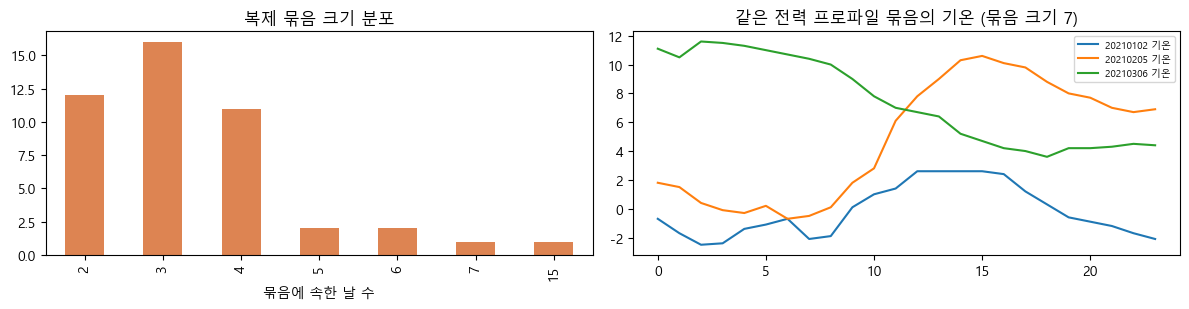

**결론: 최대 묶음 15일은 전력 21~26 수준의 비가동 프로파일로 평일(화·수)까지 포함. 복제일끼리 전력은 같지만 기상은 0/45 묶음만 일치 → 같은 전력에 서로 다른 기상이 붙어 있어 기상→전력 관계를 학습하면 왜곡됨**

In [23]:
top = days.groupby('grp')['grp_size'].first().sort_values(ascending=False)
g0 = top.index[0]
g0_days = days.loc[days['grp'] == g0, 'date']
print('가장 큰 묶음 크기:', top.iloc[0], '/ 날짜:', g0_days.dt.strftime('%m-%d(%a)').tolist())
g0_row = df[df['날짜'] == days.loc[days['grp'] == g0, '날짜'].iloc[0]]
print('해당 프로파일 전력 범위:', g0_row[P].values.min(), '~', g0_row[P].values.max(), '/ 생산량 합:', g0_row['생산량'].sum())

res = []
for c in ['생산량', '공장인원', '기온', '습도', '강수량']:
    pc = df.pivot(index='날짜', columns='row_h', values=c).fillna(-999)
    kc = pc.apply(lambda r: tuple(r.values), axis=1)
    same = [kc.loc[days.loc[days['grp'] == g, '날짜']].nunique() == 1 for g in top.index[top > 1]]
    res.append((c, sum(same), len(same)))
cmp = pd.DataFrame(res, columns=['컬럼', '묶음 안에서 값까지 같은 묶음 수', '복제 묶음 수'])
display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
top[top > 1].value_counts().sort_index().plot.bar(ax=ax[0], color='#dd8452'); ax[0].set_title('복제 묶음 크기 분포'); ax[0].set_xlabel('묶음에 속한 날 수')
ex = days.loc[days['grp'] == top.index[top > 1][1], '날짜'].tolist()[:3]
for d in ex:
    ax[1].plot(df.loc[df['날짜'] == d, 'row_h'], df.loc[df['날짜'] == d, '기온'], label=f'{d} 기온')
ax[1].set_title(f'같은 전력 프로파일 묶음의 기온 (묶음 크기 {top.iloc[1]})'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
conclude(f'최대 묶음 {top.iloc[0]}일은 전력 {g0_row[P].values.min()}~{g0_row[P].values.max()} 수준의 비가동 프로파일로 평일(화·수)까지 포함. '
         f'복제일끼리 전력은 같지만 기상은 {cmp.iloc[2,1]}/{cmp.iloc[2,2]} 묶음만 일치 → 같은 전력에 서로 다른 기상이 붙어 있어 기상→전력 관계를 학습하면 왜곡됨')

## 9. 누수 없이 쓸 수 있는 구간 정의
- 시차(lag) 변수(전일·전주 같은 시각)는 **달력상 연속된 원본 날짜**가 있어야 의미가 있다. 복제된 1~6월에서 '전주 같은 시각'은 실제 전주 값이 아닐 수 있다.
- 따라서 가장 긴 연속 고유 구간을 찾는다.

원본 구간 시작(다른 달과 프로파일을 공유하는 마지막 날의 다음 날): 2021-07-01
원본 구간 안에서 서로 같은 프로파일인 날: ['07-28', '07-30']


,min,max,size
use_core,,,
10,2021-07-31,2021-09-14,46
2,2021-07-01,2021-07-12,12
6,2021-07-16,2021-07-27,12
4,2021-07-14,2021-07-14,1
8,2021-07-29,2021-07-29,1


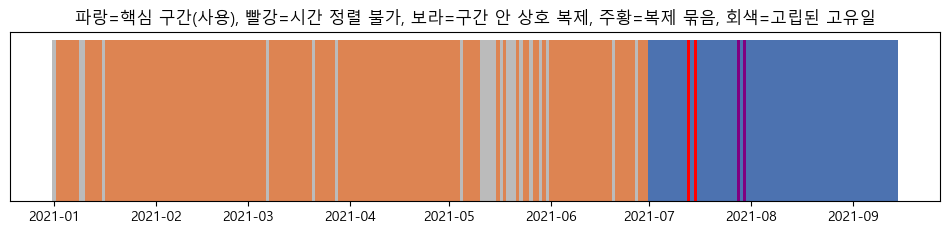

**결론: 원본 구간 07-01 ~ 09-14 (76일) 중 시간 정렬 불가 2일, 상호 복제 2일(07-28, 07-30)을 빼면 핵심 구간 72일(1,728시간). 끊김 없는 최장 연속은 07-31~09-14 46일. 1~6월 고유일 23일은 앞뒤가 복제일이라 시차 변수를 만들 수 없어 핵심 구간에서 제외**

In [24]:
# (a) 원본 구간 시작 = '다른 달의 날과 같은 프로파일을 공유하는 마지막 날'의 다음 날
grp_months = days.groupby('grp')['m'].transform('nunique')
days['cross_month_dup'] = grp_months > 1
core_start = days.loc[days['cross_month_dup'], 'date'].max() + pd.Timedelta(days=1)
late = days[days['date'] >= core_start]
late_dup = late.loc[late['dup'], 'date'].dt.strftime('%m-%d').tolist()
print('원본 구간 시작(다른 달과 프로파일을 공유하는 마지막 날의 다음 날):', f'{core_start:%Y-%m-%d}')
print('원본 구간 안에서 서로 같은 프로파일인 날:', late_dup)

# (b) 플래그: 시간 정렬 불가, 구간 안 상호 복제(어느 쪽이 원본인지 판단 불가 → 둘 다 제외)
days['flag_time_bad'] = days['날짜'].isin(bad_days)
days['flag_copy_in_core'] = (days['date'] >= core_start) & days['dup']
days['in_span'] = days['date'] >= core_start
days['use_core'] = days['in_span'] & ~days['flag_time_bad'] & ~days['flag_copy_in_core']

# (c) 플래그 없이 이어지는 가장 긴 연속 구간 (시차 168시간 변수에 필요한 길이 확인용)
ok = days['use_core']
blk = (ok != ok.shift()).cumsum()
runs = days[ok].groupby(blk[ok])['date'].agg(['min', 'max', 'size']).sort_values('size', ascending=False)
display(runs)

fig, ax = plt.subplots(figsize=(12, 2.2))
colors = np.where(days['use_core'], '#4c72b0', np.where(days['flag_time_bad'], 'red', np.where(days['flag_copy_in_core'], 'purple', np.where(days['dup'], '#dd8452', '#bbbbbb'))))
ax.bar(days['date'], 1, color=colors, width=1)
ax.set_yticks([]); ax.set_title('파랑=핵심 구간(사용), 빨강=시간 정렬 불가, 보라=구간 안 상호 복제, 주황=복제 묶음, 회색=고립된 고유일')
plt.show()
n_iso = ((~days['dup']) & ~days['in_span']).sum()
conclude(f'원본 구간 {core_start:%m-%d} ~ {days["date"].max():%m-%d} ({days["in_span"].sum()}일) 중 시간 정렬 불가 {days["flag_time_bad"].sum()}일, '
         f'상호 복제 {days["flag_copy_in_core"].sum()}일({", ".join(late_dup)})을 빼면 핵심 구간 {days["use_core"].sum()}일({days["use_core"].sum()*24:,}시간). '
         f'끊김 없는 최장 연속은 {runs.iloc[0]["min"]:%m-%d}~{runs.iloc[0]["max"]:%m-%d} {runs.iloc[0]["size"]}일. '
         f'1~6월 고유일 {n_iso}일은 앞뒤가 복제일이라 시차 변수를 만들 수 없어 핵심 구간에서 제외')

## 10. 상수·규칙형 변수 (정보량 점검)

,변수,고유값,결정 요인
0,인건비,"[1.5, 1.0]","시각(09~17시=1.0) — 위반 날짜 [20210713, 20210715]"
1,전기요금(계절),"[109.8, 167.2, 191.6]","월 — {1: 109.8, 2: 109.8, 3: 167.2, 4: 167.2, 5..."


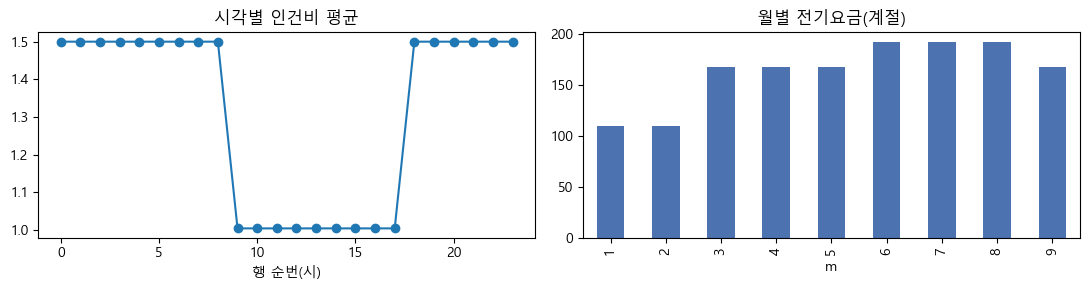

**결론: 인건비는 시각, 전기요금(계절)은 월로 완전히 결정됨 → 예측 입력으로 추가 정보 없음. 최적화 단계의 비용 계수로만 사용**

In [25]:
rule = pd.DataFrame({
  '변수': ['인건비', '전기요금(계절)'],
  '고유값': [df['인건비'].unique().tolist(), df['전기요금(계절)'].unique().tolist()],
  '결정 요인': ['시각(09~17시=1.0) — 위반 날짜 ' + str(labor_bad_days), '월 — ' + str(df.groupby('m')['전기요금(계절)'].first().to_dict())]})
display(rule)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
df.groupby('row_h')['인건비'].mean().plot(ax=ax[0], marker='o'); ax[0].set_title('시각별 인건비 평균'); ax[0].set_xlabel('행 순번(시)')
df.groupby('m')['전기요금(계절)'].first().plot.bar(ax=ax[1], color='#4c72b0'); ax[1].set_title('월별 전기요금(계절)')
plt.tight_layout(); plt.show()
conclude('인건비는 시각, 전기요금(계절)은 월로 완전히 결정됨 → 예측 입력으로 추가 정보 없음. 최적화 단계의 비용 계수로만 사용')

## 11. 생산량·공장인원의 척도 (핵심 구간)

            생산량      공장인원
count  1728.000  1711.000
mean    510.655     0.855
std     924.800     1.483
min       0.000     0.000
25%       0.000     0.000
50%      69.500     0.168
75%     685.500     1.162
max    7913.000    13.166


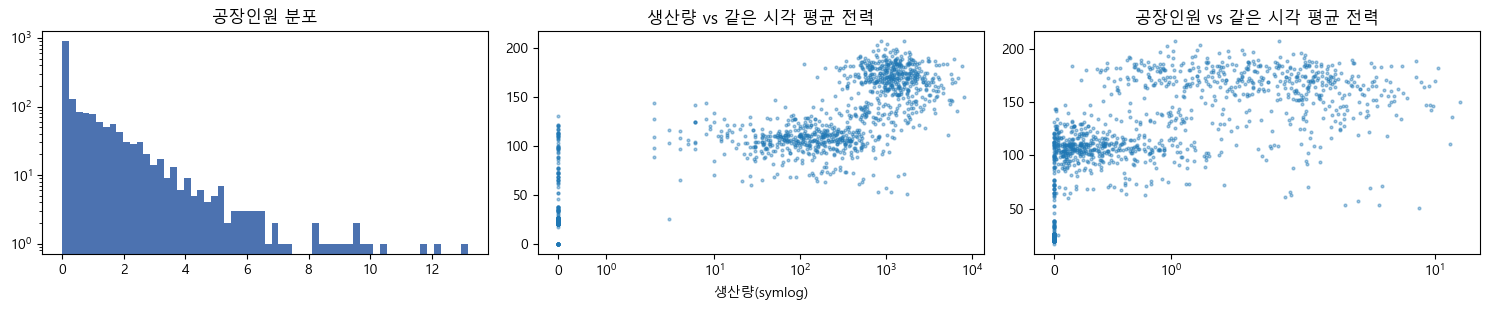

**결론: 공장인원은 소수 값 비율 60%, 최대 13.2 → 사람 수가 아니라 비율형 지표(정의 미확인). 생산량(ERP 계획값)·공장인원과 같은 시각 전력의 순위상관 0.88·0.85 (상관이며 인과 아님)**

In [26]:
core = df[df['날짜'].isin(days.loc[days['use_core'], '날짜'])].copy()
print(core[['생산량', '공장인원']].describe().round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].hist(core['공장인원'].dropna(), bins=60, color='#4c72b0'); ax[0].set_title('공장인원 분포'); ax[0].set_yscale('log')
ax[1].scatter(core['생산량'], core['평균'], s=4, alpha=0.4); ax[1].set_xscale('symlog'); ax[1].set_title('생산량 vs 같은 시각 평균 전력'); ax[1].set_xlabel('생산량(symlog)')
ax[2].scatter(core['공장인원'], core['평균'], s=4, alpha=0.4); ax[2].set_xscale('symlog'); ax[2].set_title('공장인원 vs 같은 시각 평균 전력')
plt.tight_layout(); plt.show()
frac = ((core['공장인원'] % 1) != 0).mean()
r_p = core[['생산량', '평균']].corr(method='spearman').iloc[0, 1]
r_w = core[['공장인원', '평균']].corr(method='spearman').iloc[0, 1]
conclude(f'공장인원은 소수 값 비율 {frac:.0%}, 최대 {core["공장인원"].max():.1f} → 사람 수가 아니라 비율형 지표(정의 미확인). '
         f'생산량(ERP 계획값)·공장인원과 같은 시각 전력의 순위상관 {r_p:.2f}·{r_w:.2f} (상관이며 인과 아님)')

## 12. 핵심 구간의 전력 구조: 시각 × 요일, 비가동 기간

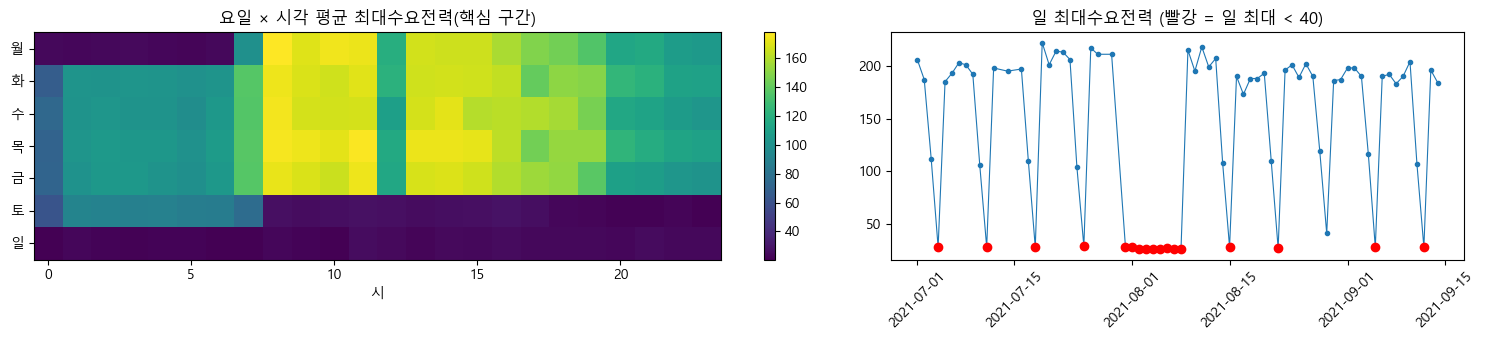

**결론: 핵심 구간 일 최대 < 40인 날 17일(07-04, 07-11, 07-18, 07-25, 07-31, 08-01, 08-02, 08-03, 08-04, 08-05, 08-06, 08-07, 08-08, 08-15, 08-22, 09-05, 09-12) → 평일 포함 연속 비가동 기간 존재(휴가 추정, 확인 불가). 이 날들은 피크 예측 평가에서 따로 표기해야 함**

In [27]:
core['hmax'] = core[P].max(axis=1)          # 한 시간 안 15분 최대수요전력의 최댓값
hm = core.pivot_table(index='day', columns='row_h', values='hmax', aggfunc='mean')
dmax = core.groupby('date')['hmax'].max()
idle = dmax[dmax < 40]
fig, ax = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw={'width_ratios': [3, 2]})
im = ax[0].imshow(hm, aspect='auto', cmap='viridis')
ax[0].set_yticks(range(7), ['월', '화', '수', '목', '금', '토', '일']); ax[0].set_xlabel('시'); ax[0].set_title('요일 × 시각 평균 최대수요전력(핵심 구간)')
plt.colorbar(im, ax=ax[0])
ax[1].plot(dmax.index, dmax.values, marker='.', lw=0.8); ax[1].scatter(idle.index, idle.values, color='red', zorder=3)
ax[1].set_title('일 최대수요전력 (빨강 = 일 최대 < 40)'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
conclude(f'핵심 구간 일 최대 < 40인 날 {len(idle)}일({", ".join(idle.index.strftime("%m-%d"))}) → 평일 포함 연속 비가동 기간 존재(휴가 추정, 확인 불가). '
         f'이 날들은 피크 예측 평가에서 따로 표기해야 함')

## 13. 요금 관점의 목표: 월 최대수요전력은 몇 시간이 만드는가
가이드북 문제 정의(원문 요지): "3개월 간의 최대 피크 전력을 기준으로 1년간의 전기료를 부과" → 피크 시간대를 줄이는 것이 목적.

,월,시간 수,월 최대,10번째,최대-10번째,상위 1%(개),최대 발생 시각
0,7,648,222,207,15,7,[11]
1,8,744,218,201,17,8,[8]
2,9,336,204,191,13,4,[9]


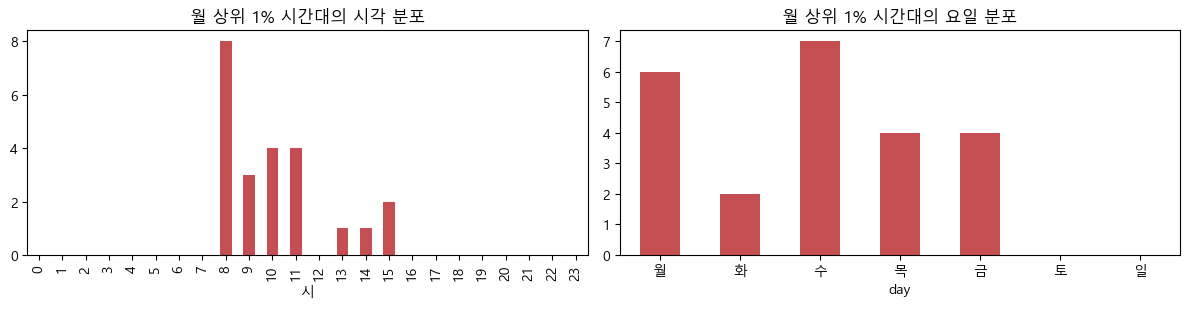

**결론: 핵심 구간 월 상위 1% 시간대 23개 중 08시 비율 35%. 피크 사건 수가 월 수 개 수준 → 분류 문제로 바꾸면 양성 표본이 매우 적음. "08시 고정 경보" 같은 단순 규칙을 반드시 기준선에 포함해야 함**

In [28]:
core['month'] = core['date'].dt.month
rows = []
for m, g in core.groupby('month'):
    s = g['hmax'].sort_values(ascending=False).values
    top_h = g.loc[g['hmax'] == s[0], 'row_h'].tolist()
    rows.append({'월': m, '시간 수': len(g), '월 최대': s[0], '10번째': s[9], '최대-10번째': s[0] - s[9],
                 '상위 1%(개)': int(np.ceil(len(g) * 0.01)), '최대 발생 시각': top_h})
tbl = pd.DataFrame(rows); display(tbl)
thr = core.groupby('month')['hmax'].transform(lambda s: s.quantile(0.99))
toph = core[core['hmax'] >= thr]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
toph['row_h'].value_counts().sort_index().reindex(range(24), fill_value=0).plot.bar(ax=ax[0], color='#c44e52')
ax[0].set_title('월 상위 1% 시간대의 시각 분포'); ax[0].set_xlabel('시')
toph['day'].value_counts().sort_index().reindex(range(1, 8), fill_value=0).plot.bar(ax=ax[1], color='#c44e52')
ax[1].set_xticklabels(['월', '화', '수', '목', '금', '토', '일'], rotation=0); ax[1].set_title('월 상위 1% 시간대의 요일 분포')
plt.tight_layout(); plt.show()
h8 = (toph['row_h'] == 8).mean()
conclude(f'핵심 구간 월 상위 1% 시간대 {len(toph)}개 중 08시 비율 {h8:.0%}. 피크 사건 수가 월 수 개 수준 → '
         f'분류 문제로 바꾸면 양성 표본이 매우 적음. "08시 고정 경보" 같은 단순 규칙을 반드시 기준선에 포함해야 함')

## 14. 진단표 저장

In [29]:
import os
os.makedirs('results_ro', exist_ok=True)
diag = pd.DataFrame([
 ('행 단위', '1행 = 1시간, 15분 구간 4개(15/30/45/60분) + 평균(반올림 파생값)'),
 ('기간', f'{df.date.min():%Y-%m-%d} ~ {df.date.max():%Y-%m-%d}, {df["날짜"].nunique()}일, 빠진 날 {len(missing_days)}'),
 ('시간 컬럼 오류', f'{bad_mask.sum()}행 / {bad_days}: 전력 열 시간 정렬 확인 불가, 인건비·생산량도 규칙 위반 → 전력 제외 플래그'),
 ('행 순서', f'인접 행 경계 변화 {bnd.mean():.1f} vs 무작위 {shuf.mean():.1f} → 대체로 시간순'),
 ('결측', f'풍속 {na["풍속"].sum()}, 강수량 {na["강수량"].sum()}, 공장인원 {na["공장인원"].sum()}(연속 구간)'),
 ('복제', f'고유 프로파일 {gid.nunique()}/{len(days)}일, 복제 묶음 소속 {days["dup"].sum()}일, 기상은 복제되지 않음'),
 ('핵심 분석 구간', f'{core_start:%Y-%m-%d} ~ {days["date"].max():%Y-%m-%d} 중 {days["use_core"].sum()}일 (제외: 시간 정렬 불가 {bad_days}, 상호 복제 {late_dup})'),
 ('정보 없는 변수', '인건비(시각 결정), 전기요금(월 결정), 평균(15분 컬럼 파생)'),
 ('비가동 기간', f'핵심 구간 {len(idle)}일'),
 ('피크 집중', f'월 상위 1% 시간대 중 08시 {h8:.0%}'),
], columns=['항목', '결과'])
display(diag)
diag.to_csv('results_ro/01_diagnosis.csv', index=False, encoding='utf-8-sig')
days[['날짜', 'grp', 'grp_size', 'dup', 'in_span', 'flag_time_bad', 'flag_copy_in_core', 'use_core']].to_csv('results_ro/01_day_flags.csv', index=False, encoding='utf-8-sig')
with open('results_ro/environment.json', 'w') as f: json.dump(env, f, ensure_ascii=False)
conclude('진단표와 날짜별 플래그(results_ro/01_day_flags.csv)를 저장. 다음 노트북은 이 플래그만 읽어 구간을 정하고, 다시 계산하지 않는다')

,항목,결과
0,행 단위,"1행 = 1시간, 15분 구간 4개(15/30/45/60분) + 평균(반올림 파생값)"
1,기간,"2021-01-01 ~ 2021-09-14, 257일, 빠진 날 0"
2,시간 컬럼 오류,"48행 / [20210713, 20210715]: 전력 열 시간 정렬 확인 불가, ..."
3,행 순서,인접 행 경계 변화 12.4 vs 무작위 64.4 → 대체로 시간순
4,결측,"풍속 3, 강수량 1, 공장인원 17(연속 구간)"
5,복제,"고유 프로파일 142/257일, 복제 묶음 소속 160일, 기상은 복제되지 않음"
6,핵심 분석 구간,2021-07-01 ~ 2021-09-14 중 72일 (제외: 시간 정렬 불가 [2...
7,정보 없는 변수,"인건비(시각 결정), 전기요금(월 결정), 평균(15분 컬럼 파생)"
8,비가동 기간,핵심 구간 17일
9,피크 집중,월 상위 1% 시간대 중 08시 35%


**결론: 진단표와 날짜별 플래그(results_ro/01_day_flags.csv)를 저장. 다음 노트북은 이 플래그만 읽어 구간을 정하고, 다시 계산하지 않는다**